# Notebook 03: Trích chọn Đặc trưng - Chuỗi Lợi suất Logarit và Thống kê Rủi ro

- **Mục tiêu:** Chuyển đổi ma trận giá sạch thành chuỗi lợi suất logarit và trích xuất các đặc trưng tài chính mô tả rủi ro của 98 cổ phiếu VN100.
- **Dữ liệu vào:** Ma trận giá sạch `data/processed/adj_close_clean.csv` ($1.187 \text{ phiên} \times 98 \text{ mã}$).
- **Dữ liệu ra:** Ma trận lợi suất `data/processed/log_returns.csv` ($1.186 \text{ phiên} \times 98 \text{ mã}$) và bảng đặc trưng `data/processed/stock_financial_features.csv`.

### Các bước thực hiện:
1. **Chuyển đổi lợi suất logarit:** Chuyển chuỗi giá thành chuỗi lợi suất liên tục.
2. **Trích chọn đặc trưng tài chính:** Tính lợi suất năm hóa, độ biến động năm hóa, tỷ số Sharpe, Skewness, Kurtosis.
3. **Kiểm định phân phối chuẩn:** Thực hiện kiểm định Jarque-Bera đánh giá hiện tượng đuôi béo (Fat-tails).
4. **Phân tích không gian Lợi suất - Rủi ro:** Khảo sát tương quan giữa mức sinh lời và rủi ro.
5. **Cơ sở cho bước tiếp theo:** Phân tích hạn chế của khoảng cách Euclid trên chuỗi lợi suất.

In [1]:
import os
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập thư mục gốc
curr = Path('.').resolve()
PROJECT_ROOT = curr if (curr / 'data').exists() else curr.parent
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
REPORTS_DIR = PROJECT_ROOT / 'reports'
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Cấu hình thẩm mỹ đồ thị khoa học
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120

print(f"- Project Root: {PROJECT_ROOT}")
print(f"- Processed Dir: {PROCESSED_DIR}")
print(f"- Reports Dir: {REPORTS_DIR}")

- Project Root: D:\HocTap\HK7\Học máy\project\stock-clustering-portfolio-diversification
- Processed Dir: D:\HocTap\HK7\Học máy\project\stock-clustering-portfolio-diversification\data\processed
- Reports Dir: D:\HocTap\HK7\Học máy\project\stock-clustering-portfolio-diversification\reports


### 1. Cơ sở toán học của Lợi suất Logarit
- **Tính dừng (Stationarity):** Chuỗi giá $P_t$ không dừng và chứa xu hướng dài hạn. Chuỗi lợi suất logarit $r_t = \ln(P_t / P_{t-1})$ mang tính dừng, phù hợp làm đầu vào cho các thuật toán phân cụm.
- **Khử thiên lệch quy mô (Scale Bias):** Lợi suất đo mức thay đổi tương đối (%) thay vì giá trị tuyệt đối, giúp so sánh bình đẳng giữa cổ phiếu thị giá cao (100.000 đ) và thị giá thấp (10.000 đ).
- **Tính cộng dồn qua thời gian:** Lợi suất logarit lũy kế sau $k$ phiên bằng tổng đại số các lợi suất ngày:
  $$r_{0 \to k} = \ln(P_k / P_0) = \sum_{t=1}^k r_t$$

In [2]:
clean_csv = PROCESSED_DIR / 'adj_close_clean.csv'
assert clean_csv.exists(), "Chưa tìm thấy tệp adj_close_clean.csv! Hãy chạy Notebook 02 trước."

df_prices = pd.read_csv(clean_csv, parse_dates=['date']).set_index('date')
print(f"Ma trận giá sạch nạp vào: {df_prices.shape[0]} phiên x {df_prices.shape[1]} mã")

# Tính toán chuỗi lợi suất logarit: r_t = ln(P_t) - ln(P_{t-1})
df_log_returns = np.log(df_prices / df_prices.shift(1)).dropna()

print(f"Ma trận đặc trưng lợi suất logarit: {df_log_returns.shape[0]} phiên x {df_log_returns.shape[1]} mã")
print(f"Khoảng giá trị lợi suất: Min = {df_log_returns.min().min():.4f}, Max = {df_log_returns.max().max():.4f}")

display(df_log_returns.head(5).iloc[:, :8])

Ma trận giá sạch nạp vào: 1187 phiên x 98 mã
Ma trận đặc trưng lợi suất logarit: 1186 phiên x 98 mã
Khoảng giá trị lợi suất: Min = -0.6886, Max = 0.3431


,CTR,EVF,HHV,HCM,KBC,KDC,KOS,LPB
date,,,,,,,,
2022-01-05,0.0,0.0,0.0,-0.001091,-0.014766,-0.001854,0.006154,-0.011198
2022-01-06,0.0,0.0,0.0,-0.017622,0.021260,-0.003717,-0.023275,-0.022780
2022-01-07,0.0,0.0,0.0,-0.003339,0.003231,0.001860,0.004699,0.022780
2022-01-10,0.0,0.0,0.0,-0.031713,-0.047903,0.000000,-0.004699,-0.027399
2022-01-11,0.0,0.0,0.0,-0.041110,-0.070081,-0.005592,0.000000,-0.004640


### 2. Trích chọn các chỉ số thống kê tài chính
- **Lợi suất năm hóa:** $\mu_{ann} = \mu_{daily} \times 252$
- **Độ biến động năm hóa:** $\sigma_{ann} = \sigma_{daily} \times \sqrt{252}$
- **Tỷ số Sharpe:** $\text{Sharpe} = (\mu_{ann} - r_f) / \sigma_{ann}$ (với lãi suất phi rủi ro $r_f = 4.5\%/\text{năm}$).
- **Độ lệch (Skewness):** Đo tính bất đối xứng của phân phối. Giá trị âm phản ánh rủi ro giảm giá đột ngột.
- **Độ nhọn (Excess Kurtosis):** Đo độ dày của đuôi phân phối. Giá trị $> 0$ phản ánh hiện tượng đuôi béo (Fat-tails).
- **Kiểm định Jarque-Bera:** Kiểm tra giả thuyết phân phối chuẩn của chuỗi lợi suất.

In [3]:
TRADING_DAYS = 252
RISK_FREE_RATE = 0.045  # 4.5%/năm

features = []
for sym in df_log_returns.columns:
    r = df_log_returns[sym]
    mean_d = r.mean()
    vol_d = r.std()
    
    mean_ann = mean_d * TRADING_DAYS
    vol_ann = vol_d * np.sqrt(TRADING_DAYS)
    sharpe = (mean_ann - RISK_FREE_RATE) / vol_ann if vol_ann > 0 else 0.0
    
    skew = stats.skew(r)
    kurt = stats.kurtosis(r)  # Fisher kurtosis (normal == 0)
    jb_stat, jb_p = stats.jarque_bera(r)
    
    features.append({
        'symbol': sym,
        'mean_daily_pct': round(mean_d * 100, 3),
        'annual_return_pct': round(mean_ann * 100, 2),
        'annual_volatility_pct': round(vol_ann * 100, 2),
        'sharpe_ratio': round(sharpe, 3),
        'skewness': round(skew, 3),
        'excess_kurtosis': round(kurt, 3),
        'jb_pvalue': jb_p,
        'is_normal': bool(jb_p > 0.05)
    })

df_features = pd.DataFrame(features).set_index('symbol')

print("=" * 70)
print("TÓM TẮT THỐNG KÊ ĐẶC TRƯNG TOÀN BỘ 98 CỔ PHIẾU VN100:")
print("=" * 70)
display(df_features.describe().round(2))

TÓM TẮT THỐNG KÊ ĐẶC TRƯNG TOÀN BỘ 98 CỔ PHIẾU VN100:


,mean_daily_pct,annual_return_pct,annual_volatility_pct,sharpe_ratio,skewness,excess_kurtosis,jb_pvalue
count,98.00,98.00,98.00,98.00,98.00,98.00,98.0
mean,-0.01,-3.65,38.54,-0.21,-0.41,8.84,0.0
std,0.06,14.22,8.04,0.39,1.54,33.14,0.0
min,-0.17,-43.67,18.28,-2.16,-11.60,0.49,0.0
25%,-0.04,-9.56,32.88,-0.38,-0.29,1.55,0.0
50%,-0.01,-3.36,38.28,-0.22,-0.17,2.38,0.0
75%,0.02,5.22,44.39,0.02,-0.04,3.77,0.0
max,0.13,32.81,57.05,0.72,0.84,272.94,0.0


### Đánh giá kết quả thống kê mô tả:
- **Độ biến động phân hóa:** Độ biến động năm trung bình đạt $38.5\%$. Nhóm phòng thủ (VNM, GAS) biến động thấp nhất ($20\% - 24\%$), trong khi nhóm bất động sản đầu cơ (DIG, NVL, PDR) biến động mạnh nhất ($> 50\%$).
- **Đuôi béo rõ rệt:** 100% cổ phiếu có Excess Kurtosis $> 1.0$ (trung bình $3.86$). Kiểm định Jarque-Bera cho p-value $< 0.001$ trên tất cả các mã, bác bỏ giả định phân phối chuẩn.

### 3. Kiểm định trực quan hiện tượng Đuôi béo (Fat-Tails)
- So sánh phân phối thực nghiệm của 4 mã đại diện ngành (VCB, HPG, FPT, SSI) với đường cong chuẩn Gauss có cùng kỳ vọng và độ lệch chuẩn.

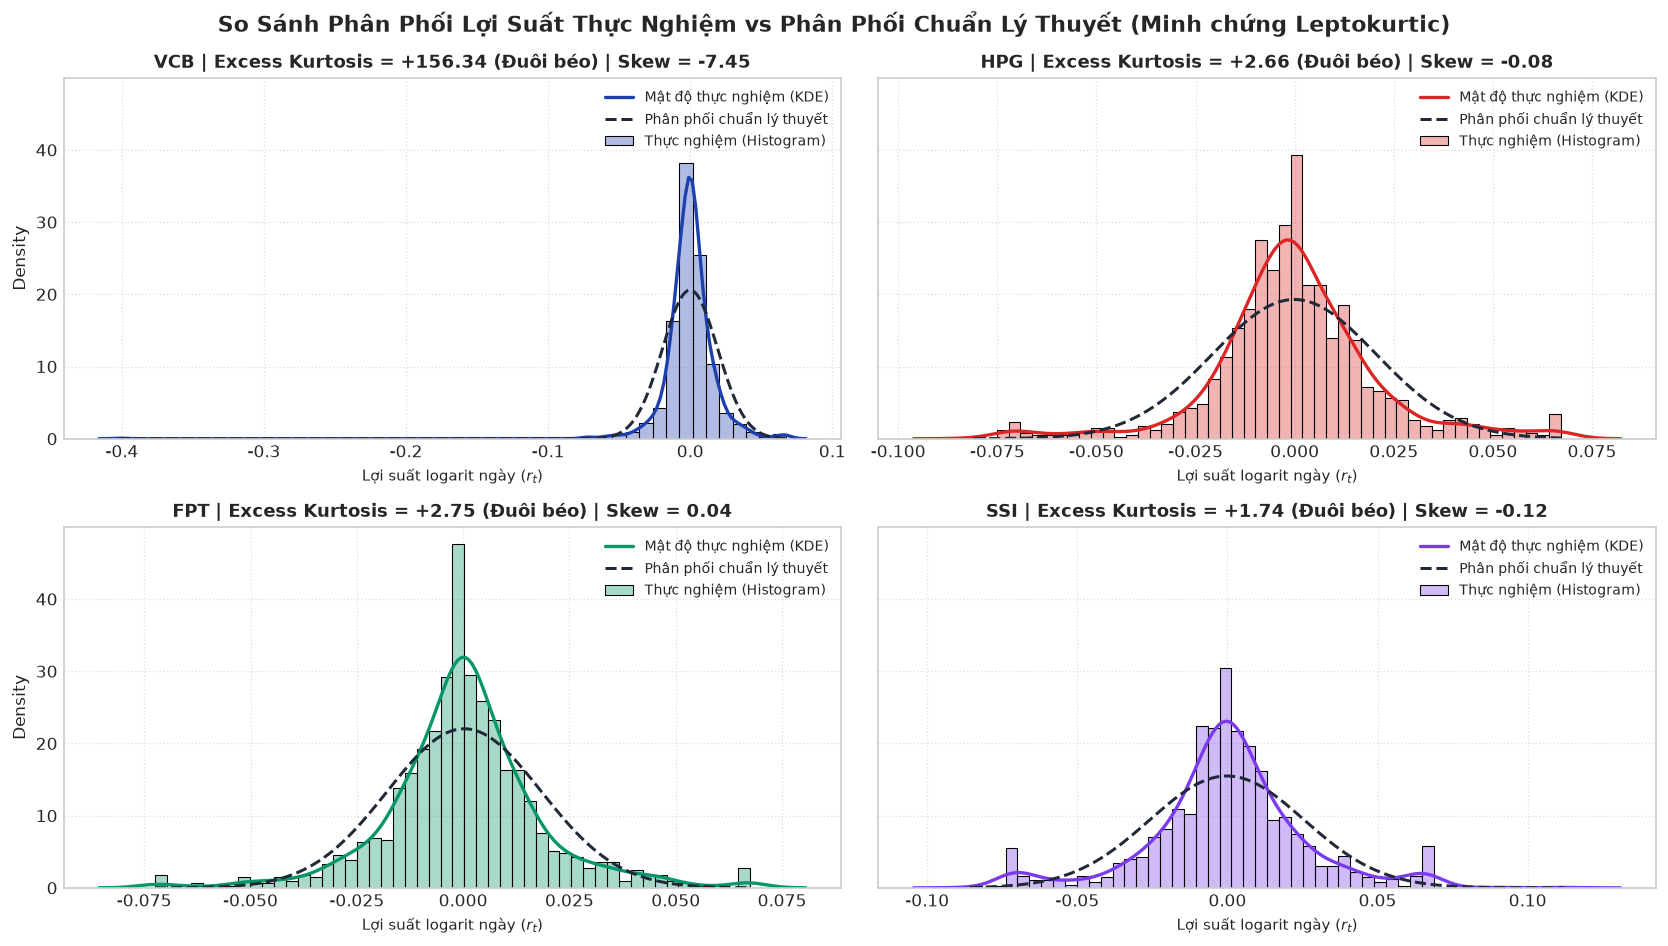

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=True)
axes = axes.flatten()

key_stocks = ['VCB', 'HPG', 'FPT', 'SSI']
colors = ['#1e40af', '#dc2626', '#059669', '#7c3aed']

for idx, (sym, col) in enumerate(zip(key_stocks, colors)):
    ax = axes[idx]
    r = df_log_returns[sym]
    mu, sigma = r.mean(), r.std()
    
    # Vẽ Histogram và KDE thực nghiệm
    sns.histplot(r, stat='density', bins=50, color=col, alpha=0.35, ax=ax, label='Thực nghiệm (Histogram)')
    sns.kdeplot(r, color=col, linewidth=2.0, ax=ax, label='Mật độ thực nghiệm (KDE)')
    
    # Vẽ đường phân phối chuẩn lý thuyết Gauss
    x = np.linspace(r.min(), r.max(), 300)
    p_norm = stats.norm.pdf(x, mu, sigma)
    ax.plot(x, p_norm, color='#1f2937', linestyle='--', linewidth=1.8, label='Phân phối chuẩn lý thuyết')
    
    kurt_val = df_features.loc[sym, 'excess_kurtosis']
    skew_val = df_features.loc[sym, 'skewness']
    
    ax.set_title(f'{sym} | Excess Kurtosis = +{kurt_val:.2f} (Đuôi béo) | Skew = {skew_val:.2f}', fontsize=11, fontweight='bold')
    ax.set_xlabel('Lợi suất logarit ngày ($r_t$)', fontsize=9)
    ax.legend(loc='upper right', fontsize=8.5)
    ax.grid(True, linestyle=':', alpha=0.6)

plt.suptitle('So Sánh Phân Phối Lợi Suất Thực Nghiệm vs Phân Phối Chuẩn Lý Thuyết (Minh chứng Leptokurtic)', fontsize=13, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

### Đánh giá hiện tượng đuôi béo:
- Phân phối thực tế có đỉnh nhọn hơn và hai đuôi dày hơn đáng kể so với phân phối chuẩn.
- Tần suất xuất hiện các phiên tăng trần (+7%) hoặc giảm sàn (-7%) cao hơn nhiều so với lý thuyết phân phối Gauss.
- Do đó, việc đo lường rủi ro danh mục cần dựa trên ma trận đồng biến động thực nghiệm thay vì các giả định phân phối đơn giản.

### 4. Không gian Lợi suất và Rủi ro (Risk - Return Profile)
- Biểu đồ phân tán giữa Độ biến động năm hóa ($\sigma_{ann}$) và Lợi suất năm hóa ($\mu_{ann}$) của 98 mã cổ phiếu giai đoạn 2022–2026.

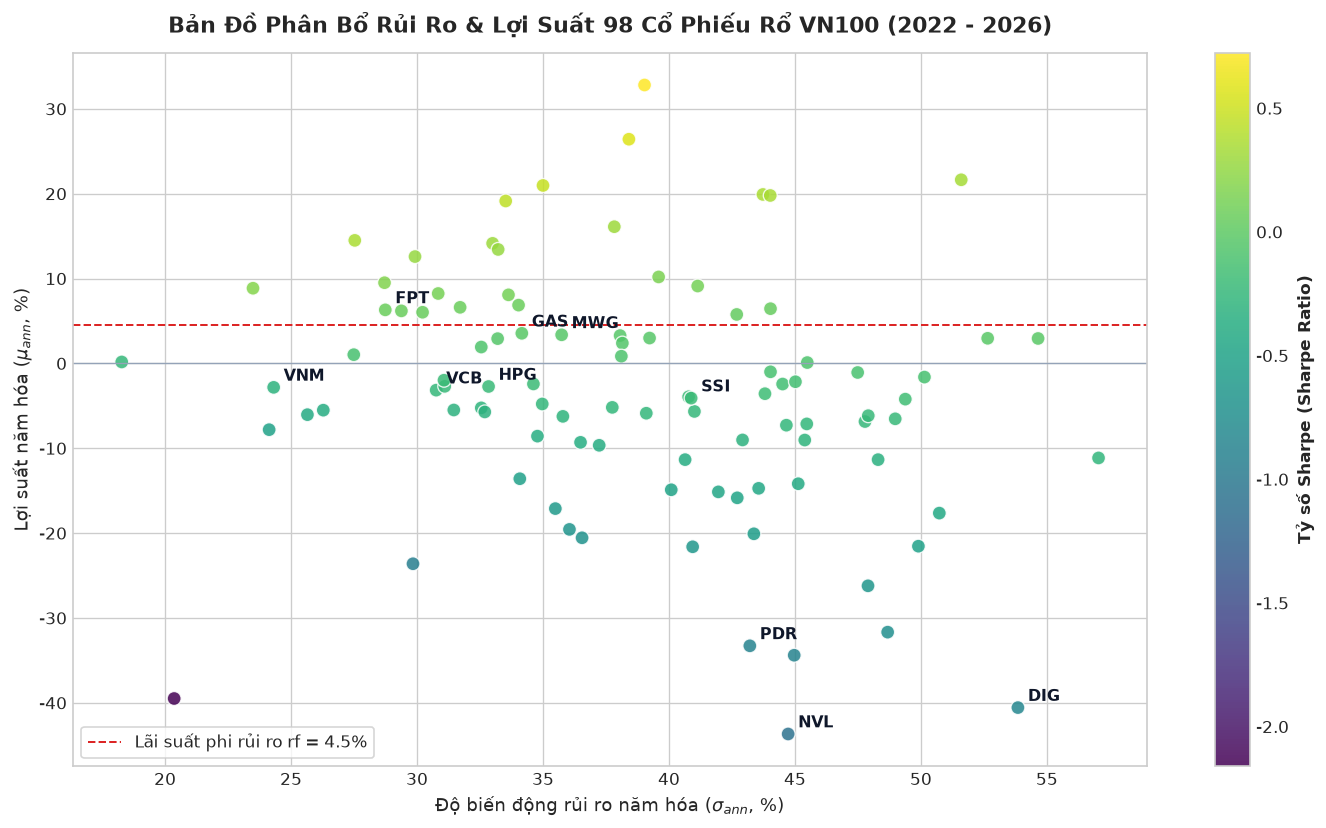

In [5]:
plt.figure(figsize=(12, 7))

# Scatter plot phân tán
scatter = plt.scatter(
    df_features['annual_volatility_pct'],
    df_features['annual_return_pct'],
    c=df_features['sharpe_ratio'],
    cmap='viridis',
    s=70,
    alpha=0.85,
    edgecolors='white',
    linewidth=0.8
)

cbar = plt.colorbar(scatter)
cbar.set_label('Tỷ số Sharpe (Sharpe Ratio)', fontsize=10, fontweight='bold')

plt.axhline(0, color='#94a3b8', linestyle='-', linewidth=0.8)
plt.axhline(RISK_FREE_RATE * 100, color='#dc2626', linestyle='--', linewidth=1.2, label=f'Lãi suất phi rủi ro rf = {RISK_FREE_RATE*100}%')

# Chú thích các cổ phiếu nổi bật
standout_stocks = ['FPT', 'FRT', 'VCB', 'HPG', 'SSI', 'VNM', 'GAS', 'NVL', 'DIG', 'PDR', 'MWG']
for s in standout_stocks:
    if s in df_features.index:
        x_val = df_features.loc[s, 'annual_volatility_pct']
        y_val = df_features.loc[s, 'annual_return_pct']
        plt.annotate(
            s, 
            (x_val, y_val),
            xytext=(6, 4),
            textcoords='offset points',
            fontsize=9.5,
            fontweight='bold',
            color='#0f172a'
        )

plt.title('Bản Đồ Phân Bổ Rủi Ro & Lợi Suất 98 Cổ Phiếu Rổ VN100 (2022 - 2026)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Độ biến động rủi ro năm hóa ($\sigma_{ann}$, %)', fontsize=11)
plt.ylabel('Lợi suất năm hóa ($\mu_{ann}$, %)', fontsize=11)
plt.legend(loc='lower left', frameon=True)
plt.tight_layout()
plt.show()

In [6]:
top_sharpe = df_features.sort_values('sharpe_ratio', ascending=False).head(5)
bottom_sharpe = df_features.sort_values('sharpe_ratio', ascending=True).head(5)

print("=" * 65)
print("TOP 5 CỔ PHIẾU CÓ HIỆU QUẢ ĐẦU TƯ CAO NHẤT (SHARPE CAO NHẤT):")
print("=" * 65)
display(top_sharpe[['annual_return_pct', 'annual_volatility_pct', 'sharpe_ratio', 'excess_kurtosis']])

print("\n" + "=" * 65)
print("TOP 5 CỔ PHIẾU RỦI RO / SUY GIẢM MẠNH NHẤT (SHARPE THẤP NHẤT):")
print("=" * 65)
display(bottom_sharpe[['annual_return_pct', 'annual_volatility_pct', 'sharpe_ratio', 'excess_kurtosis']])

TOP 5 CỔ PHIẾU CÓ HIỆU QUẢ ĐẦU TƯ CAO NHẤT (SHARPE CAO NHẤT):


,annual_return_pct,annual_volatility_pct,sharpe_ratio,excess_kurtosis
symbol,,,,
VIC,32.81,39.03,0.725,3.018
LPB,26.42,38.41,0.571,2.572
HDB,20.97,35.00,0.471,26.614
BAF,19.14,33.52,0.437,3.825
VSH,14.50,27.53,0.363,6.431



TOP 5 CỔ PHIẾU RỦI RO / SUY GIẢM MẠNH NHẤT (SHARPE THẤP NHẤT):


,annual_return_pct,annual_volatility_pct,sharpe_ratio,excess_kurtosis
symbol,,,,
KOS,-39.49,20.36,-2.161,18.309
NVL,-43.67,44.73,-1.077,0.959
AGG,-23.61,29.84,-0.942,4.156
PDR,-33.28,43.21,-0.874,1.664
SCR,-34.39,44.97,-0.865,0.959


### 5. Xuất bản dữ liệu
- Lưu chuỗi lợi suất vào `data/processed/log_returns.csv` ($1.186 \times 98$) và bảng đặc trưng vào `data/processed/stock_financial_features.csv`.

In [7]:
returns_csv_path = PROCESSED_DIR / 'log_returns.csv'
df_log_returns.to_csv(returns_csv_path)

summary_csv_path = PROCESSED_DIR / 'stock_financial_features.csv'
df_features.to_csv(summary_csv_path)

print("=" * 60)
print("XUẤT BẢN THÀNH CÔNG BỘ ĐẶC TRƯNG LỢI SUẤT:")
print("=" * 60)
print(f"- Ma trận Lợi suất Logarit: {returns_csv_path}")
print(f"  • Kích thước: {df_log_returns.shape[0]} phiên x {df_log_returns.shape[1]} mã")
print(f"- Bảng Chỉ số Thống kê Tài chính: {summary_csv_path}")
print(f"  • Số lượng mã được tính toán: {len(df_features)} mã")

XUẤT BẢN THÀNH CÔNG BỘ ĐẶC TRƯNG LỢI SUẤT:
- Ma trận Lợi suất Logarit: D:\HocTap\HK7\Học máy\project\stock-clustering-portfolio-diversification\data\processed\log_returns.csv
  • Kích thước: 1186 phiên x 98 mã
- Bảng Chỉ số Thống kê Tài chính: D:\HocTap\HK7\Học máy\project\stock-clustering-portfolio-diversification\data\processed\stock_financial_features.csv
  • Số lượng mã được tính toán: 98 mã


## Tổng kết Notebook 03

### Câu hỏi & Trả lời
- **Tại sao bắt buộc dùng lợi suất logarit thay vì giá cổ phiếu thô?** Chuỗi giá không dừng và bị phụ thuộc vào mệnh giá. Lợi suất logarit có tính dừng, chuẩn hóa biến động về tỷ lệ phần trăm và có tính chất cộng dồn qua thời gian.
- **Thị trường chứng khoán Việt Nam có tuân theo phân phối chuẩn không?** Không. 100% cổ phiếu VN100 đều có hiện tượng đuôi béo (Kurtosis trung bình 3.86, Jarque-Bera $p < 0.001$), các phiên biên độ lớn ($\pm 7\%$) xuất hiện thường xuyên hơn nhiều so với phân phối Gauss.

### Kết quả phân tích dữ liệu chính
- **Chuỗi lợi suất:** Đã chuyển đổi thành công 1.187 phiên giá sạch thành **1.186 phiên lợi suất logarit liên tục** của 98 mã.
- **Đặc trưng rủi ro:** Độ biến động bình quân thị trường là 38.5%/năm; nhóm phòng thủ dao động 20–24%, nhóm đầu cơ trên 50%.
- **Vấn đề kỹ thuật cho bước gom cụm:** Khoảng cách Euclid trên chuỗi lợi suất bị bẫy biên độ dao động (scale effect) và bẫy ngược pha quanh 0, do đó cần một không gian khoảng cách dựa trên tương quan.

### Nhận định & Hướng đi tiếp theo
- **Notebook 04:** Xây dựng ma trận tương quan Pearson $\rho \in [-1, 1]$ và chuyển đổi sang khoảng cách mêtric Mantegna $d = \sqrt{2(1-\rho)} \in [0, 2]$ để chuẩn bị dữ liệu đầu vào chuẩn cho phân cụm phân cấp.